# Markowitz Model (Modern Portfolio)

- It was first formulated by Harry Markowitz in 1952.
- He was later awarded with the Nobel Prize in Economics.
- It is a portfolio optimization model.

**Portfolio**: A portfolio is a collection of financical investments such as stocks, bonds, commodities and cash.

- Markowitz Model assists in the selection of the most efficient portfolio by considering various possible portfolios of the given securities based on Expected Return (Mean) and Risk (Variance)

## Main Idea behind Markowitz Model

- if we want to invest all of our money into a single stock then we take a huge risk because stocks are volatile
- **A single stock is quite risky - because it is unpredictable we do not know for certain whether the S(t) stock price will rise or fall.**
- we may combine multiple assets(stocks) in order to reduce risk as much as possible.
- The main conclusion of Markowitz Model is DIVERSIFICATION.

## Assumptions of Markowitz Model

1. **Returns are Normally Distributed:**: The returns of the stocks are normally distributed with $\mu$ Mean and $\sigma$ standard deviation
2. **Investors are risk averse**: Investors will take on more risk if they are expecting more return.

- If there is a low risk (bonds) the return is low as well.
- with higher risk (stocks) the returns are usually higher.
- Modern Portfolios offering the maximum possible expected return for a given level of risk.

**SO THE EFFICIENT PORTFOLIO IS THE PORTFOLIO THAT HAS THE HIGHEST REWARD FOR A GIVEN LEVEL OF RISK OR THE LOWEST RISK FOR A GIVEN RETURN**

- The investors are not allowed to setup short positions in a security so 100% of the wealth has to be divided among available assets (stocks) in a way that all positions are long positions.

Wi -> this is the weight for the ith asset or stock
ri -> this is the return for the ith asset or stock (historical data).
$\mu$ i -> this is the expected return for the ith asset or stock (Mean of the stock).

$$
ri = 
\frac{S(t+1) - S(t)}{S(t)}
$$

{this is how we can calculate the daily return of a stock.}

we have to consider neighboring [t, t+1] time steps

Usually Log of the returns is used 


$$
\ln\!\left(\frac{S(t+1)}{S(t)}\right)
$$



### Importing Libraries

In [1]:
import numpy as np
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as optimization

### Downloading Stocks

In [2]:
stocks = ["AAPL", "WMT", "TSLA", "GE", "AMZN", "DB"]
start_date = "2020-01-01"
end_date = "2025-10-01"

def download_data(stocks):

    stock_data = {}

    for stock in stocks:
        ticker = yf.Ticker(stock)
        stock_data[stock] = ticker.history(start=start_date, end=end_date)['Close']

    return pd.DataFrame(stock_data)


stock_df = download_data(stocks)
stock_df.head()

,AAPL,WMT,TSLA,GE,AMZN,DB
Date,,,,,,
2020-01-02 00:00:00-05:00,72.538506,36.508110,28.684000,57.897743,94.900497,7.472999
2020-01-03 00:00:00-05:00,71.833282,36.185806,29.534000,58.091877,93.748497,7.284605
2020-01-06 00:00:00-05:00,72.405701,36.112144,30.102667,58.916904,95.143997,7.230777
2020-01-07 00:00:00-05:00,72.065147,35.777561,31.270666,58.480129,95.343002,7.401229
2020-01-08 00:00:00-05:00,73.224419,35.654793,32.809334,57.946278,94.598503,7.688308


### Visualization

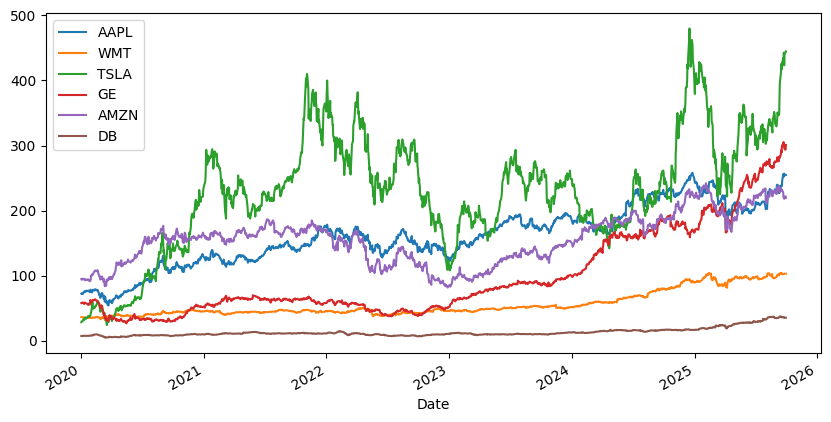

In [3]:
def show_data(data):
    data.plot(figsize=(10, 5))
    plt.show()

show_data(stock_df)

### Formula

$$
\text{Linear = } \frac{S(t+1) - S(t)}{S(t)}
$$

$$
\text{Log = } \ln\!\left(\frac{S(t+1)}{S(t)}\right)
$$


In [ ]:
def calculate_return(data):
    # S(t) / S(t-1) 
    # Theoritically S(t + 1) / S(t)
    # Why Log return due to normalization
    log_return = np.log(data / data.shift(1)) 
    # print(log_return)
    return log_return[1:]

returns_df = calculate_return(stock_df)
returns_df.head()



,AAPL,WMT,TSLA,GE,AMZN,DB
Date,,,,,,
2020-01-03 00:00:00-05:00,-0.009770,-0.008867,0.029203,0.003347,-0.012213,-0.025533
2020-01-06 00:00:00-05:00,0.007937,-0.002038,0.019072,0.014102,0.014776,-0.007417
2020-01-07 00:00:00-05:00,-0.004715,-0.009308,0.038067,-0.007441,0.002089,0.023300
2020-01-08 00:00:00-05:00,0.015958,-0.003437,0.048033,-0.009171,-0.007839,0.038055
2020-01-09 00:00:00-05:00,0.021018,0.010278,-0.022189,-0.002516,0.004788,0.004656


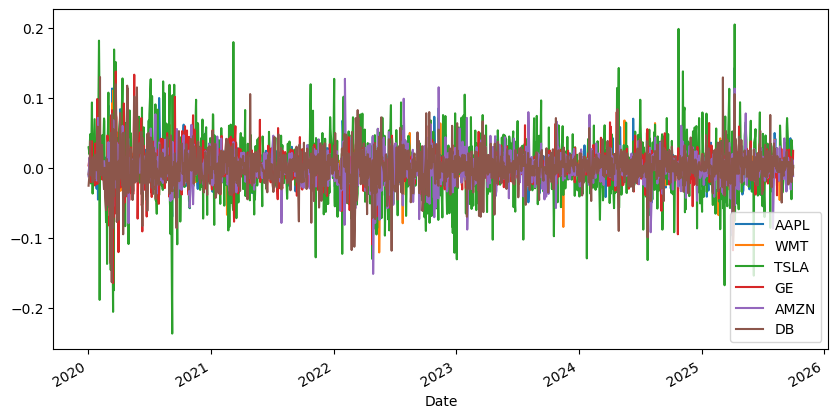

In [5]:
show_data(returns_df)

### Formulas

#### Expected Returns (Mean of the portfolio)
$$
\text{Expected Returns = } \mu_p = \sum_{i=1}^{n} w_i \mu_i
= w^T \mu
$$

#### Expected Risk (Variance)

$$
\text{Expected Risk = } \sigma_p^2 = \mathbf{w}^\top \Sigma \mathbf{w}
$$



In [ ]:
NUM_OF_TRADING_DAYS = 252
def show_statisttics(returns, num_of_trading_days=252):
    # Means of the Annual Returns
    means = returns.mean() * num_of_trading_days
    cov = returns.cov() * num_of_trading_days
    return means, cov

def show_mean_variance(returns, weights, num_of_trading_days=252):
    portfolio_returns = np.sum(returns.mean() * weights) * num_of_trading_days
    
    # Steps
    #transpose_of_w = weights.T
    #total_variance_of_trading_days = returns.cov() * num_of_trading_days
    #covariances_of_all_stocks_with_weights = np.dot(total_variance_of_trading_days, weights)
    #portfolio_volatility_variance = np.dot(transpose_of_w, covariances_of_all_stocks_with_weights)
    #portfolio_volatility = np.sqrt(portfolio_volatility_variance)
    
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(returns.cov() * num_of_trading_days, weights)))
    return portfolio_returns, portfolio_volatility

def show_portfolios(returns, volatilities):
    plt.figure(figsize=(10, 6))
    plt.scatter(volatilities, returns, c=returns/volatilities, marker="o")
    plt.grid(True)
    plt.xlabel("Expected Volatility")
    plt.ylabel("Expected Returns")
    plt.colorbar(label="Sharpe Ratio")
    plt.show()

NUM_PORTFOLIOS = 10000

def generate_portfolios(returns, num_portfolios=10000, num_of_trading_days=252):

    portfolio_means, portfolio_risks, portfolio_weights = [], [], []

    for _ in range(num_portfolios):
        w = np.random.random(len(stocks))
        # Sum of w should be 1 (100%)
        w /= np.sum(w)
        portfolio_weights.append(w)
        portfolio_means.append(np.sum(returns.mean() * w) * num_of_trading_days)
        portfolio_risks.append(
            np.sqrt(np.dot(w.T, np.dot(returns.cov() * num_of_trading_days, w)))
        )
    return np.array(portfolio_weights), np.array(portfolio_means), np.array(portfolio_risks)

means, cov = show_statisttics(returns_df)
print(f"Average Returns of the stocks are\n{means}\n\n")
print(f"Covariance of the stocks are\n{cov}\n\n")

# portfolio_returns, portfolio_volatility = show_mean_variance(returns_df, weights)
# print(f"Expected Porfolio Returns (Means)\n{portfolio_returns}\n\n")
# print(f"Expected Porfolio Volatility (Standard Deviation)\n{portfolio_volatility}\n\n")

Average Returns of the stocks are
AAPL    0.219290
WMT     0.181233
TSLA    0.478696
GE      0.287771
AMZN    0.146492
DB      0.271681
dtype: float64


Covariance of the stocks are
          AAPL       WMT      TSLA        GE      AMZN        DB
AAPL  0.103891  0.028327  0.108494  0.046936  0.068932  0.047894
WMT   0.028327  0.052851  0.028900  0.018735  0.025664  0.016790
TSLA  0.108494  0.028900  0.450319  0.068739  0.107852  0.078656
GE    0.046936  0.018735  0.068739  0.149085  0.040039  0.086530
AMZN  0.068932  0.025664  0.107852  0.040039  0.128336  0.043855
DB    0.047894  0.016790  0.078656  0.086530  0.043855  0.176588




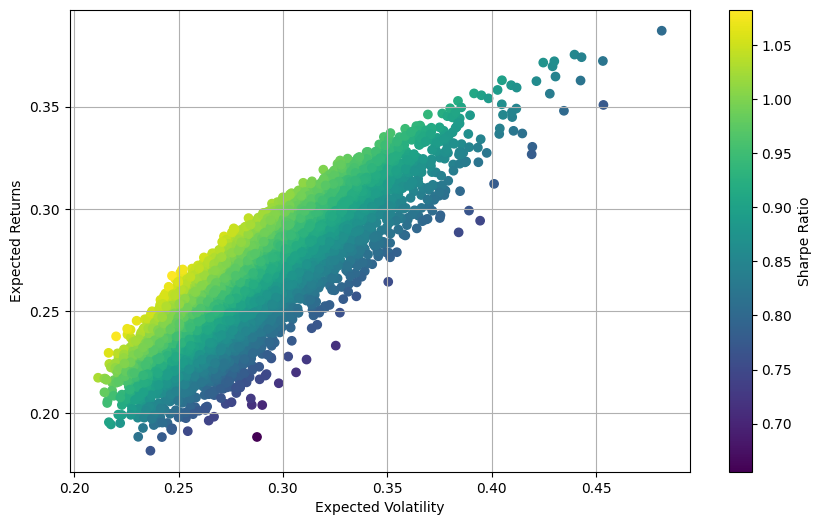

In [18]:
weights, means, risks = generate_portfolios(returns_df)

show_portfolios(means, risks)

$$
\text{Sharpe Ratio} = \frac{r_x - R_f}{\sigma_x}
$$
where
$$
r_x = \text{average rate of return on investment $x$} \\
R_f = \text{risk-free rate of return} \\
\sigma_x = \text{standard deviation of returns of $x$}
$$

a Sharpe-ratio S(x) > 1 is considered to be good


In [29]:
def statistics(weights, returns, num_of_trading_days=252):
    portfolio_returns = np.sum(returns.mean() * weights) * num_of_trading_days
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(returns.cov() * num_of_trading_days, weights)))
    sharpe_ratio = portfolio_returns / portfolio_volatility
    return np.array([portfolio_returns, portfolio_volatility, sharpe_ratio])

# scipy optimizie module can find the minimum of a given function
# the maximum of a f(x) is the minimum of -f(x)
def min_function_sharpe(weights, returns):
    return -statistics(weights, returns)[2]

# What are constraints> The sum of weights = 1
# f(x)=0 this is the function to minimize
def optimize_portfolio(weights, returns):
    # the sum of weights is 1
    constraints = {"type": "eq", "fun": lambda x: np.sum(x) -1}
    # the weights can be 1 at most: 1 when 100% of money is invested into a single stock
    bounds = tuple((0, 1) for _ in range(len(stocks)))
    return optimization.minimize(
        fun=min_function_sharpe, x0=weights[0], 
        args=returns, method="SLSQP", 
        bounds=bounds, constraints=constraints
    )

def print_optimal_portfolio(optimum, returns):
    print(f"Optimal Portfolio: {optimum['x'].round(3)}")
    print(f"Expected Return, volatility and sharpe ratio: {statistics(optimum['x'].round(3), returns)}")

def show_optimal_portfolio(opt, rets, portfolio_rets, portfolio_vols):
    plt.figure(figsize=(10, 6))
    plt.scatter(
        portfolio_vols,
        portfolio_rets,
        c=portfolio_rets/portfolio_vols,
        marker="o"
    )
    plt.grid(True)
    plt.xlabel("Expected Volatility")
    plt.ylabel("Expected Returns")
    plt.colorbar(label="Sharpe Ratio")
    plt.plot(
        statistics(opt['x'], rets)[1],
        statistics(opt['x'], rets)[0],
        "g*"
    )
    plt.show()


In [ ]:
p_weights , means, risks = generate_portfolios(returns_df)
optimum = optimize_portfolio(p_weights, returns_df)


In [27]:
print_optimal_portfolio(optimum, returns_df)

Optimal Portfolio: [0.013 0.533 0.136 0.212 0.    0.106]
Expected Return, volatility and sharpe ratio: [0.25435657 0.23163354 1.09809903]


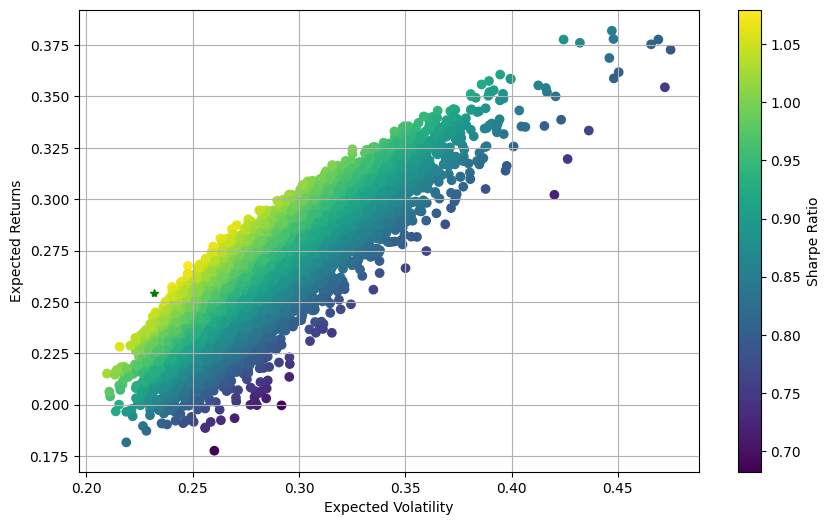

In [30]:
show_optimal_portfolio(optimum, returns_df, means, risks)

In [32]:
np.array([0.013,0.533,0.136,0.212,0,0.106]).sum()

np.float64(1.0)

# ALL AT ONCE

In [3]:
import numpy as np
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as optimization


NUM_OF_TRADING_DAYS = 252
NUM_PORTFOLIOS = 10000

class MarkowitzModel:

    def __init__(self, stocks, start_date, end_date):
        self.stocks = stocks
        self.start_date = start_date
        self.end_date = end_date

    def download_data(self):

        stock_data = {}

        for stock in self.stocks:
            ticker = yf.Ticker(stock)
            stock_data[stock] = ticker.history(start=self.start_date, end=self.end_date)['Close']

        return pd.DataFrame(stock_data)

    def show_data(self, data):
        data.plot(figsize=(10, 5))
        plt.show()

    def calculate_return(self, data):
        # S(t) / S(t-1) 
        # Theoritically S(t + 1) / S(t)
        # Why Log return due to normalization
        log_return = np.log(data / data.shift(1)) 
        # print(log_return)
        return log_return[1:]
    
    def show_statistics(self, returns, num_of_trading_days=252):
    # Means of the Annual Returns
        means = returns.mean() * num_of_trading_days
        cov = returns.cov() * num_of_trading_days
        return means, cov
    
    def show_portfolios(self, returns, volatilities):
        plt.figure(figsize=(10, 6))
        plt.scatter(volatilities, returns, c=returns/volatilities, marker="o")
        plt.grid(True)
        plt.xlabel("Expected Volatility")
        plt.ylabel("Expected Returns")
        plt.colorbar(label="Sharpe Ratio")
        plt.show()

    def generate_portfolios(self, returns, num_portfolios=10000, num_of_trading_days=252):

        portfolio_means, portfolio_risks, portfolio_weights = [], [], []

        for _ in range(num_portfolios):
            w = np.random.random(len(self.stocks))
            # Sum of w should be 1 (100%)
            w /= np.sum(w)
            portfolio_weights.append(w)
            portfolio_means.append(np.sum(returns.mean() * w) * num_of_trading_days)
            portfolio_risks.append(
                np.sqrt(np.dot(w.T, np.dot(returns.cov() * num_of_trading_days, w)))
            )
        return np.array(portfolio_weights), np.array(portfolio_means), np.array(portfolio_risks)
    
    def statistics(self, weights, returns, num_of_trading_days=252):
        portfolio_returns = np.sum(returns.mean() * weights) * num_of_trading_days
        portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(returns.cov() * num_of_trading_days, weights)))
        sharpe_ratio = portfolio_returns / portfolio_volatility
        return np.array([portfolio_returns, portfolio_volatility, sharpe_ratio])
    
    def min_function_sharpe(self, weights, returns):
        return -self.statistics(weights, returns)[2]
    
    def optimize_portfolio(self, weights, returns):
        # the sum of weights is 1
        constraints = {"type": "eq", "fun": lambda x: np.sum(x) -1}
        # the weights can be 1 at most: 1 when 100% of money is invested into a single stock
        bounds = tuple((0, 1) for _ in range(len(self.stocks)))
        return optimization.minimize(
            fun=self.min_function_sharpe, x0=weights[0], 
            args=returns, method="SLSQP", 
            bounds=bounds, constraints=constraints
        )
    
    def print_optimal_portfolio(self, optimum, returns):
        print(f"Optimal Portfolio: {optimum['x'].round(3)}")
        print(f"Expected Return, volatility and sharpe ratio: {self.statistics(optimum['x'].round(3), returns)}")

    def show_optimal_portfolio(self, opt, rets, portfolio_rets, portfolio_vols):
        plt.figure(figsize=(10, 6))
        plt.scatter(
            portfolio_vols,
            portfolio_rets,
            c=portfolio_rets/portfolio_vols,
            marker="o"
        )
        plt.grid(True)
        plt.xlabel("Expected Volatility")
        plt.ylabel("Expected Returns")
        plt.colorbar(label="Sharpe Ratio")
        plt.plot(
            self.statistics(opt['x'], rets)[1],
            self.statistics(opt['x'], rets)[0],
            "g*"
        )
        plt.show()


In [26]:
stocks = ["ADANIENT.NS", "BAJAJFINSV.NS", "HPL.NS", "JINDALSTEL.NS", "MEGASOFT.BO", "TRIDENT.BO"]
start_date = "2024-10-01"
end_date = "2025-10-03"


In [27]:
mm = MarkowitzModel(stocks, start_date, end_date)
stocks_df = mm.download_data()
stocks_df.head()

,ADANIENT.NS,BAJAJFINSV.NS,HPL.NS,JINDALSTEL.NS,MEGASOFT.BO,TRIDENT.BO
Date,,,,,,
2024-10-01 00:00:00+05:30,3184.471924,1974.288086,565.080200,1033.300049,68.769997,36.431747
2024-10-03 00:00:00+05:30,3114.407471,1912.468262,546.069580,1048.969116,65.860001,35.377892
2024-10-04 00:00:00+05:30,3109.060303,1883.632324,551.458374,1019.078308,67.480003,35.052872
2024-10-07 00:00:00+05:30,3016.457764,1878.384888,517.578552,998.618896,64.480003,33.605057
2024-10-08 00:00:00+05:30,3159.084717,1837.254883,557.795288,980.953979,64.550003,34.461929


In [28]:
stocks_df.tail()

,ADANIENT.NS,BAJAJFINSV.NS,HPL.NS,JINDALSTEL.NS,MEGASOFT.BO,TRIDENT.BO
Date,,,,,,
2025-09-25 00:00:00+05:30,2576.399902,2035.599976,478.750000,1051.699951,165.800003,29.09
2025-09-26 00:00:00+05:30,2543.699951,2003.199951,463.549988,1029.500000,158.449997,28.68
2025-09-29 00:00:00+05:30,2509.500000,2024.699951,453.700012,1043.349976,152.300003,28.17
2025-09-30 00:00:00+05:30,2505.899902,2006.400024,456.149994,1063.750000,153.100006,28.16
2025-10-01 00:00:00+05:30,2592.699951,2007.000000,461.000000,1065.000000,156.199997,28.33


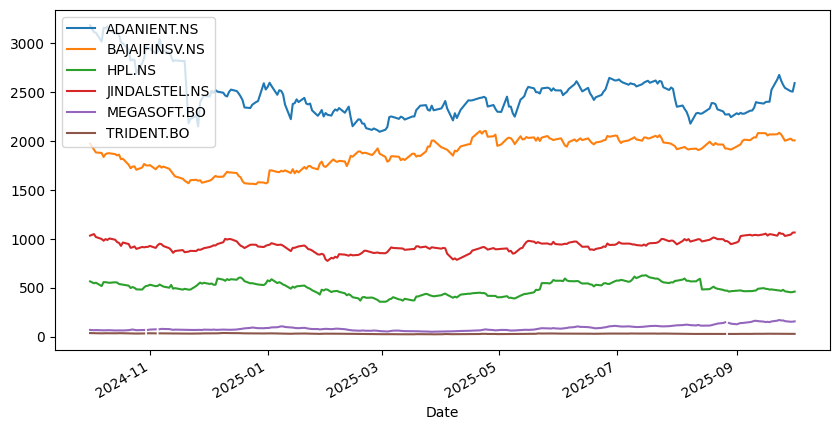

In [29]:
mm.show_data(stocks_df)

In [30]:
returns_df = mm.calculate_return(stocks_df)
returns_df.head()

,ADANIENT.NS,BAJAJFINSV.NS,HPL.NS,JINDALSTEL.NS,MEGASOFT.BO,TRIDENT.BO
Date,,,,,,
2024-10-03 00:00:00+05:30,-0.022248,-0.031813,-0.034221,0.015050,-0.043236,-0.029353
2024-10-04 00:00:00+05:30,-0.001718,-0.015193,0.009820,-0.028909,0.024300,-0.009230
2024-10-07 00:00:00+05:30,-0.030237,-0.002790,-0.063405,-0.020281,-0.045476,-0.042181
2024-10-08 00:00:00+05:30,0.046199,-0.022140,0.074831,-0.017848,0.001085,0.025179
2024-10-09 00:00:00+05:30,-0.002201,0.015546,-0.002149,0.016748,0.007101,0.006836


In [31]:
means, cov = mm.show_statistics(returns_df)
print(f"Average Returns of the stocks are\n{means}\n\n")
print(f"Covariance of the stocks are\n{cov}\n\n")

Average Returns of the stocks are
ADANIENT.NS     -0.207231
BAJAJFINSV.NS    0.016565
HPL.NS          -0.205198
JINDALSTEL.NS    0.030459
MEGASOFT.BO      0.878684
TRIDENT.BO      -0.301397
dtype: float64


Covariance of the stocks are
               ADANIENT.NS  BAJAJFINSV.NS    HPL.NS  JINDALSTEL.NS  \
ADANIENT.NS       0.186946       0.036023  0.076456       0.045669   
BAJAJFINSV.NS     0.036023       0.060429  0.017457       0.028111   
HPL.NS            0.076456       0.017457  0.284918       0.047020   
JINDALSTEL.NS     0.045669       0.028111  0.047020       0.089265   
MEGASOFT.BO       0.044077       0.002799  0.077688       0.026814   
TRIDENT.BO        0.062718       0.023347  0.072586       0.042890   

               MEGASOFT.BO  TRIDENT.BO  
ADANIENT.NS       0.044077    0.062718  
BAJAJFINSV.NS     0.002799    0.023347  
HPL.NS            0.077688    0.072586  
JINDALSTEL.NS     0.026814    0.042890  
MEGASOFT.BO       0.276446    0.047477  
TRIDENT.BO        0.047477 

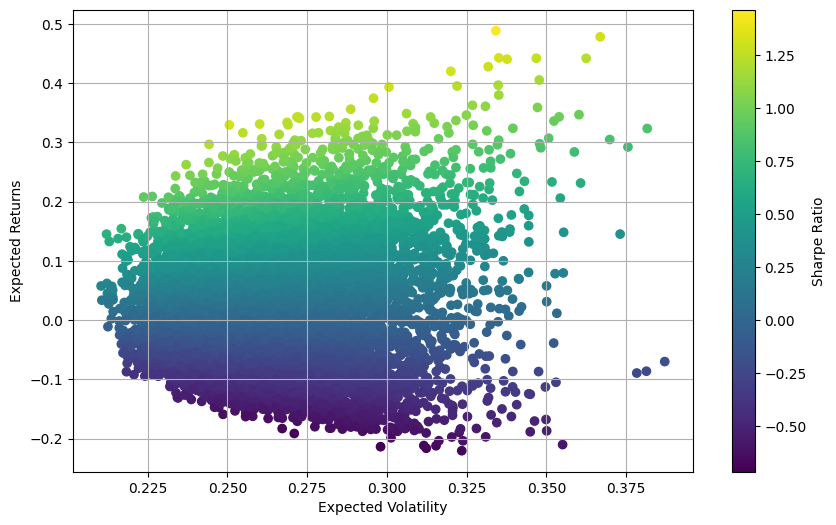

In [32]:
weights, means, risks = mm.generate_portfolios(returns_df)
mm.show_portfolios(means, risks)

In [33]:
p_weights , means, risks = mm.generate_portfolios(returns_df)
optimum = mm.optimize_portfolio(p_weights, returns_df)

In [34]:
mm.print_optimal_portfolio(optimum, returns_df)

Optimal Portfolio: [0.    0.038 0.    0.    0.962 0.   ]
Expected Return, volatility and sharpe ratio: [0.84592384 0.50608978 1.67148969]


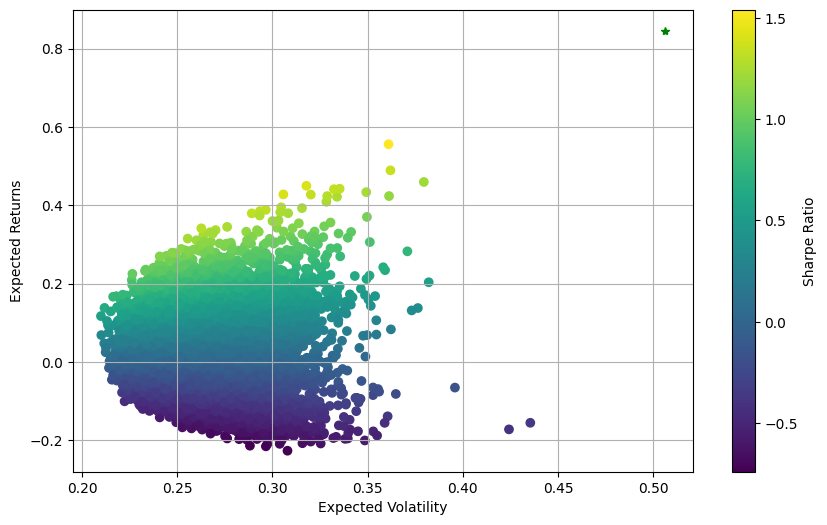

In [35]:
mm.show_optimal_portfolio(optimum, returns_df, means, risks)